# BACCO in a joint two-point and three-point Fisher forecast

Gas ejection changes how matter clusters inside and around halos. A power spectrum describes correlations of two density fluctuations; a bispectrum describes correlations of three. BACCO's **Burger2025** models supply both changes using the same gas parameters. We pass their separate responses to the shear correlations $\xi_\pm$ and the third-order aperture moment $\langle M_{\rm ap}^3\rangle$ (Map3). We do not infer a bispectrum response by taking a power of the power-spectrum response.

This notebook tests the resulting *conditional* forecast: it varies $\sigma_8$, two gas parameters and two intrinsic-alignment amplitudes, while all other parameters remain fixed. It asks whether the joint vector separates those responses, and how that answer changes under explicit neutrino and Fourier extrapolation assumptions. It keeps all 400 two-point and 80 aperture observable bins, including their cross-covariance. Their row definitions come from the public simulation reference products; this forecast uses theory derivatives and does not fit the saved vector values. A separate [25-parameter YAML](configs/des_y3_bacco_fisher.yaml) releases the other declared cosmological and nuisance parameters.

**This is a model and numerical study, not a reproduced DES posterior or a calibrated constraint on feedback.** [BACCO model description](../../external_modules/code/cosmolike_core/theory/bacco_bispectrum/README.md#bacco) derives the conversion, continuation and remaining physical assumptions. The [estimator guide](README.md#estimator) describes the archived triangle geometry and its remaining measurement differences.

Before running the physical cases, prepare the generated table in `chains/` from the activated `Cocoa/` directory:

```bash
python projects/des_3pcf/scripts/run_3pcf.py prepare \
  projects/des_3pcf/configs/des_y3_bacco_fisher.yaml
```

The source distribution and survey covariance remain inputs in `data/`. Existing theory tables require an explicit `--overwrite`; previously saved forecasts are checked against their input identity.


## Why neutrinos require an explicit choice

BACCO predicts ratios for **cold matter**, meaning cold dark matter plus baryons. Lensing responds to total matter, which also includes massive neutrinos. For mass fraction $f_\nu=\Omega_\nu/\Omega_m$, CAMB supplies the total nonlinear power $P_{m,\mathrm{NL}}$ and the linear massive-neutrino power $P_{\nu,L}$. Define the cold amplitude fraction

$$a(k,z)=1-f_\nu\sqrt{P_{\nu,L}(k,z)/P_{m,\mathrm{NL}}(k,z)},\qquad n=1-a.$$

For a cold power response $R_{P,c}$, the default conversion is $R_{P,m}=(n+a\sqrt{R_{P,c}})^2$. It keeps the neutrino auto-power fixed and changes the cold-neutrino cross-power with the cold amplitude. This is a coherent-cross approximation: it assumes a cross-correlation coefficient of one. The alternative `cold_on_total` applies the cold ratio directly to the total spectrum.

For a triangle, write $q_i=\sqrt{R_{P,c}(k_i)}$, where $i$ visits its three sides. The independent cold bispectrum response $R_{B,c}$ enters as

$$R_{B,m}=\prod_{i=1}^{3}(n_i+a_iq_i)+\left(\prod_{i=1}^{3}a_i\right)\left[R_{B,c}-\prod_{i=1}^{3}q_i\right].$$

The first product assigns a cold or neutrino amplitude to each leg. The second term replaces its all-cold contribution by BACCO's separate bispectrum prediction. **The mixed bispectra are an assumed template, not emulator outputs.** Even the all-neutrino term is assigned by this template; using linear neutrino power does not turn the construction into a perturbative neutrino-bispectrum calculation. Here $a(k,z)$ is an amplitude fraction, not the cosmic expansion factor. Both conversions return the cold responses when neutrinos are massless or when their clustering vanishes, $P_{\nu,L}=0$; the latter is the smooth-neutrino limit.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import os
from pathlib import Path
import sys
import importlib

for variable in (
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "BLIS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
    "OMP_NUM_THREADS",
):
    os.environ[variable] = "1"
os.environ["OMP_THREAD_LIMIT"] = "4"
# BACCO uses JAX for these small preparation calls; no GPU is requested.
os.environ["JAX_PLATFORMS"] = "cpu"
os.environ["TF_NUM_INTRAOP_THREADS"] = "1"
os.environ["TF_NUM_INTEROP_THREADS"] = "1"
os.environ["XLA_FLAGS"] = (
    "--xla_cpu_multi_thread_eigen=false intra_op_parallelism_threads=1"
)
PROJECT = Path.cwd()
if not (PROJECT / "README.md").is_file():
    raise ValueError("Use des_3pcf as this notebook's working directory.")
CORE = PROJECT.parents[1] / "external_modules" / "code" / "cosmolike_core"
sys.path.insert(0, str(PROJECT / "interface"))
sys.path.insert(0, str(CORE))
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
from threadpoolctl import threadpool_info, threadpool_limits
import cosmolike_des_3pcf_bacco_wrappers as study
import json
from IPython.display import Markdown, display

blas_limit = threadpool_limits(limits=1, user_api="blas")
for library in threadpool_info():
    if library["user_api"] == "blas" and library["num_threads"] != 1:
        raise RuntimeError("A loaded BLAS library has more than one worker.")
plots = importlib.import_module(name="cosmolike_notebook_utils.3pcf")
# Figure style of the whole notebook: the shared plotting functions never change
# rcParams, so these lines set every font, tick and grid default.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90
response_plots = importlib.import_module(
    name="cosmolike_notebook_utils.3pcf.derivative_templates",
)
output = PROJECT / "chains/bacco_figures"
output.mkdir(parents=True, exist_ok=True)

## Inputs and the conditional parameter space

| Choice | Meaning in this calculation |
|---|---|
| Massive neutrinos | Fixed total mass $0.06$ eV, split over three species |
| $\sigma_8$ | RMS linear total-density contrast in spheres of radius $8\,h^{-1}\mathrm{Mpc}$ at redshift zero; CAMB supplies the distinct cold-matter $\sigma_{8,c}$ to BACCO at every displaced cosmology |
| `M_c_baccoemu` | $\log_{10}[M_c/(h^{-1}M_\odot)]$, controlling gas retention |
| `eta_baccoemu` | $\log_{10}\eta$, controlling the extent of ejected gas |
| $A_1,A_2$ | Linear-alignment and quadratic tidal-torquing amplitudes |
| Other parameters | Fixed to the complete reference point recorded in each result |
| Priors | No Gaussian priors in this five-parameter example |
| Covariance | Fixed public Y3 simulation covariance, with every cross block retained; Gaussian forecast with no finite-mock correction |

The native `feedback_amplitude` remains exactly one. Sampling it would exponentiate an already converted total response; it would not vary a BACCO gas parameter. Both response tables are regenerated when a physical BCM coordinate or cosmology changes. The $\sigma_8$ derivatives exercise that CAMB-to-BACCO dependency.

Burger2025 has no independent $h,n_s,w_0,w_a$ or neutrino-mass coordinate. Recomputing CAMB changes the DMO baseline fully, but changes feedback only through BACCO's supported $\Omega_c,\Omega_b,\sigma_{8,c}$ inputs. Quadratic IA retains its DMO prescription. These restrictions remain assumptions even after numerical convergence.

The calculation below reads completed cases by default. Setting `RUN_CALCULATIONS=True` explicitly permits missing cases to be computed, one at a time, using four OpenMP workers and one BLAS worker. A changed input, library or calculation file makes an old archive fail its identity check; use a separate output directory for a new study.

Intrinsic alignment is the correlation of galaxy shapes with their tidal environment. The alignment fiducial is the Y3 point quoted in Gomes et al. (arXiv:2601.09133), paired here with Y3 source distributions and covariance. The mean uses TATT while the supplied covariance retains its NLA-based assumptions. The separate [finite-simulation guide](README.md#compression) describes the likelihood choices needed beyond this fixed Gaussian forecast.

In [2]:
RUN_CALCULATIONS = False
configuration = PROJECT / "configs/des_y3_bacco_fisher.yaml"
archive_directory = PROJECT / "chains/bacco_joint_study"
results = {}
records = {}
for name, settings, accuracy, stencil in study.CASES:
    arrays, record = study.run_case(
        configuration=configuration, name=name, settings=settings,
        accuracy=accuracy, stencil=stencil, output=archive_directory,
        threads=4, compute_if_missing=RUN_CALCULATIONS,
    )
    results[name] = arrays
    records[name] = record
baseline = results["baseline"]
print("Selected rows:", dict(zip(*np.unique(baseline["kind"], return_counts=True))))
reference_feedback = records["baseline"]["feedback_reference"]
print("Fiducial cold coordinates:", reference_feedback["coordinates"])
print("Neutrino mass fraction:", reference_feedback["neutrino_fraction"])
print("Exact direct restoration:", records["baseline"]["direct_restoration_exact"])

Selected rows: {'map3': 80, 'xim': 200, 'xip': 200}
Fiducial cold coordinates: {'M1_z0_cen': 10.5, 'M_c': 14.0, 'beta': -0.22, 'eta': -0.3, 'omega_baryon': 0.0463, 'omega_cold': 0.28776292659927194, 'sigma8_cold': 0.7899674755054377, 'theta_inn': -0.86}
Neutrino mass fraction: 0.004280530798366911
Exact direct restoration: True


## Model changes and numerical changes answer different questions

For a difference between two predicted means, $\Delta\mu$, we calculate $\Delta\chi^2=\Delta\mu^{\mathsf T}C^{-1}\Delta\mu$. This uses the full joint covariance $C$; it measures separation in the survey's error metric. It is not a fitted parameter bias. We do not divide by a signal that can cross zero.

The first group changes the physical continuation: the neutrino conversion, whether high-$k$ triangles retain their side ratios, the high-$k$ anchor, the low-$k$ anchor, and the continuation above redshift three. A squeezed triangle with one soft side retains the feedback response of its short-scale partners. Only an all-soft triangle tapers toward unity.

The second group refines one numerical axis at a time. `feedback_z`, `feedback_k`, `feedback_u` and `feedback_v` double the input intervals along redshift, scale, shortest/middle side ratio and the sorted-side shape coordinate $v$. `feedback_dense` changes the native cubic-to-linear upsampling factor from two to three. Its lower memory cost makes it useful for this check. A small mean change does not establish convergence of derivatives or parameter errors.

The scale-grid case also recalculates the five derivative columns. Its central-difference Fisher matrix is compared with the baseline central-difference matrix, separately from the physical model comparisons.

For sorted Fourier sides, $u=k_{\rm short}/k_{\rm middle}$ and $v=(k_{\rm long}-k_{\rm middle})/k_{\rm short}$. The latter is a shape coordinate, not an angle. The uniform preparation uses $\ln k$ and $\ln u$, with ordinary uniform $z$ and $v$ axes.

In [3]:
distances = {}
for name, arrays in results.items():
    distances[name] = study.mean_distance(reference=baseline, changed=arrays)
rows = ["| Comparison | Joint $\Delta\chi^2$ |", "|---|---:|"]
for name, value in distances.items():
    if name != "baseline":
        rows.append(f"| {name} | {value:.6g} |")
display(Markdown("\n".join(rows)))

| Comparison | Joint $\Delta\chi^2$ |
|---|---:|
| cold_on_total | 8.78481e-12 |
| side_clamp | 1.76733e-06 |
| high_k_5 | 0.0473377 |
| low_k_004 | 9.66615e-08 |
| high_z_fade | 3.81521e-15 |
| feedback_z | 1.52274e-05 |
| feedback_k | 1.95652e-05 |
| feedback_u | 3.88808e-07 |
| feedback_v | 1.96555e-09 |
| feedback_dense | 1.09595e-05 |

## What information does Map3 add?

For derivative matrix $J_{i\alpha}=\partial\mu_i/\partial p_\alpha$, the fixed-covariance Fisher matrix is $F=J^{\mathsf T}C^{-1}J$. The row index $i$ visits measurements; $\alpha$ visits the five parameters listed above. We invert the full five-parameter Fisher matrix before reading each error, so an error is marginalized over the other four varied parameters. It is still conditional on every parameter held fixed outside this example.

The figure divides each joint error by its two-point error. Values below one indicate additional information. The calculation accounts for the part of Map3 already correlated with $\xi_\pm$; it does not add two independent Fisher matrices. Both experiments use the same parameters, fiducial and prior choices. Failure to resolve a parameter combination is reported without a pseudoinverse.

A Fisher matrix is a local Gaussian approximation to the likelihood. If an inferred gas-parameter error reaches the emulator boundary, this calculation does not establish the corresponding posterior interval. Such a case requires an explicit bounded inference calculation and a valid response model throughout its support.

At the supplied fiducial, the local error in $\log_{10}\eta$ exceeds the distance to the emulator boundary. Treat the plotted ratios and feedback FoM as local-information comparisons. A bounded posterior analysis could give different interval widths and a different improvement from Map3.

The gray dashed line marks a ratio of one.

{'joint': 'resolved', 'two_point': 'resolved'}


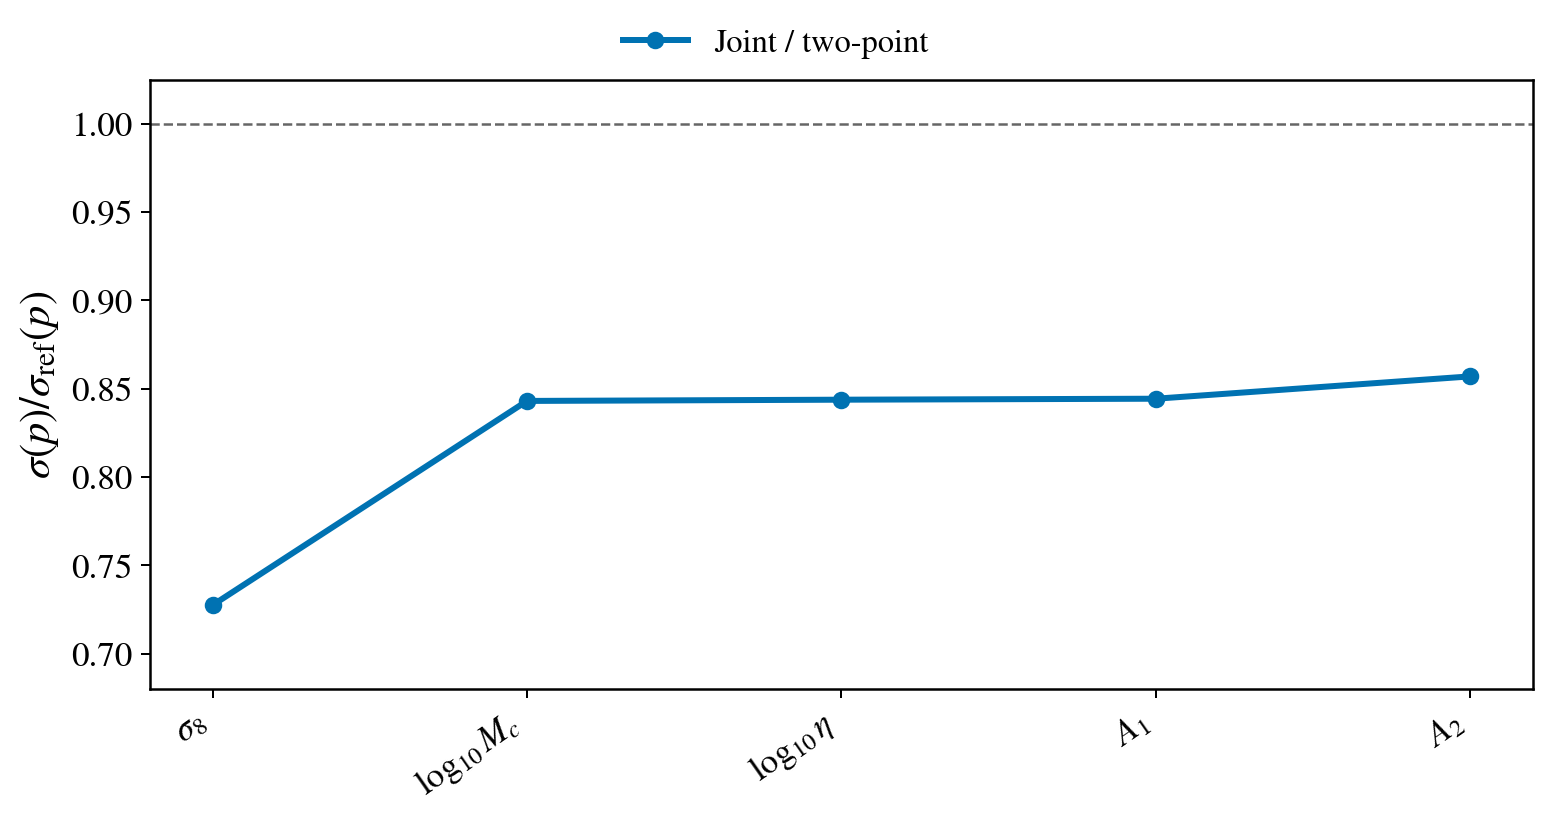

Local eta interval: -0.9509039958668593 0.35090399586685933
Installed eta bounds: [-0.69778  0.19919]
The local eta interval leaves calibration; it is not a posterior interval.


In [4]:
labels = [r"$\sigma_8$", r"$\log_{10} M_c$", r"$\log_{10}\eta$", r"$A_1$", r"$A_2$"]
print(records["baseline"]["forecasts"]["h2"]["rank_status"])
if "h2_sigma_joint" in baseline and "h2_sigma_two_point" in baseline:
    figure, axis = plots.plot_parameter_errors(
        names=list(study.PARAMETERS), errors=[baseline["h2_sigma_joint"]],
        errors_ref=baseline["h2_sigma_two_point"], labels=labels,
        legend=["Joint / two-point"], figsize=(8.5, 4.5), show=None,
    )
    axis.set_ylim(bottom=0.68, top=1.025)
    plots.check_figure_labels(figure=figure)
    figure.savefig(output / "joint_errors.png", dpi=150, pad_inches=.2)
    figure.savefig(output / "joint_errors.pdf", pad_inches=.2)
    plt.show()
else:
    print("No marginalized error plot: inspect the rank status above.")

# These limits come from the installed Burger2025 coordinate box. They
# are validity boundaries, not additional Gaussian Fisher priors.
from theory.bacco_bispectrum.emulator import BaccoColdResponses
# Read the exact interval associated with the same verified weight files.
calibration = BaccoColdResponses(
    coordinates=records["baseline"]["feedback_reference"]["coordinates"],
)
trained = calibration.bispectrum.emulator["baryon"]
eta_bounds = trained["bounds"][trained["keys"].index("eta")].copy()
del calibration
eta_center = records["baseline"]["feedback_reference"]["coordinates"]["eta"]
if "h2_sigma_joint" in baseline:
    eta_index = list(baseline["names"]).index("eta_baccoemu")
    eta_sigma = baseline["h2_sigma_joint"][eta_index]
    print("Local eta interval:", eta_center-eta_sigma, eta_center+eta_sigma)
    print("Installed eta bounds:", eta_bounds)
    if eta_center-eta_sigma < eta_bounds[0] or eta_center+eta_sigma > eta_bounds[1]:
        print("The local eta interval leaves calibration; "
              "it is not a posterior interval.")


## Read the derivatives as observable changes

Take a declared displacement $\Delta\log_{10}M_c=0.2$ and $\Delta\log_{10}\eta=0.1$. The top panels show $\Delta p\,\partial\mu_i/\partial p$ divided by the individual row error $\sigma_i=\sqrt{C_{ii}}$. These displacements make units explicit; they are neither prior widths nor the finite-difference steps. We do not normalize each curve to its own peak, because that would hide differences in response strength.

The bottom panels ask how well a change in one feedback parameter can mimic the other. One coefficient is fitted using all two-point rows, then extended to Map3 without refitting; another is fitted using the full joint covariance. The displayed panels select source-bin pair (1,1) and triplet (1,1,1), but each fit uses the entire selected vector. Different residual shapes explain why additional measurements can separate parameters even when the two-point responses resemble each other. These two-template fits keep other parameters fixed and are distinct from the five-parameter marginalized errors above.

Dividing by $\sqrt{C_{ii}}$ preserves the observable associated with each plotted point; it does not decorrelate rows. Summing the squares of those plotted numbers would therefore give the wrong $\Delta\chi^2$. The fitted coefficients use the full covariance.

The displayed displacements multiply tangent vectors. They are not predictions evaluated at those finite offsets; a nonlinear response would require evaluating the displaced model itself.

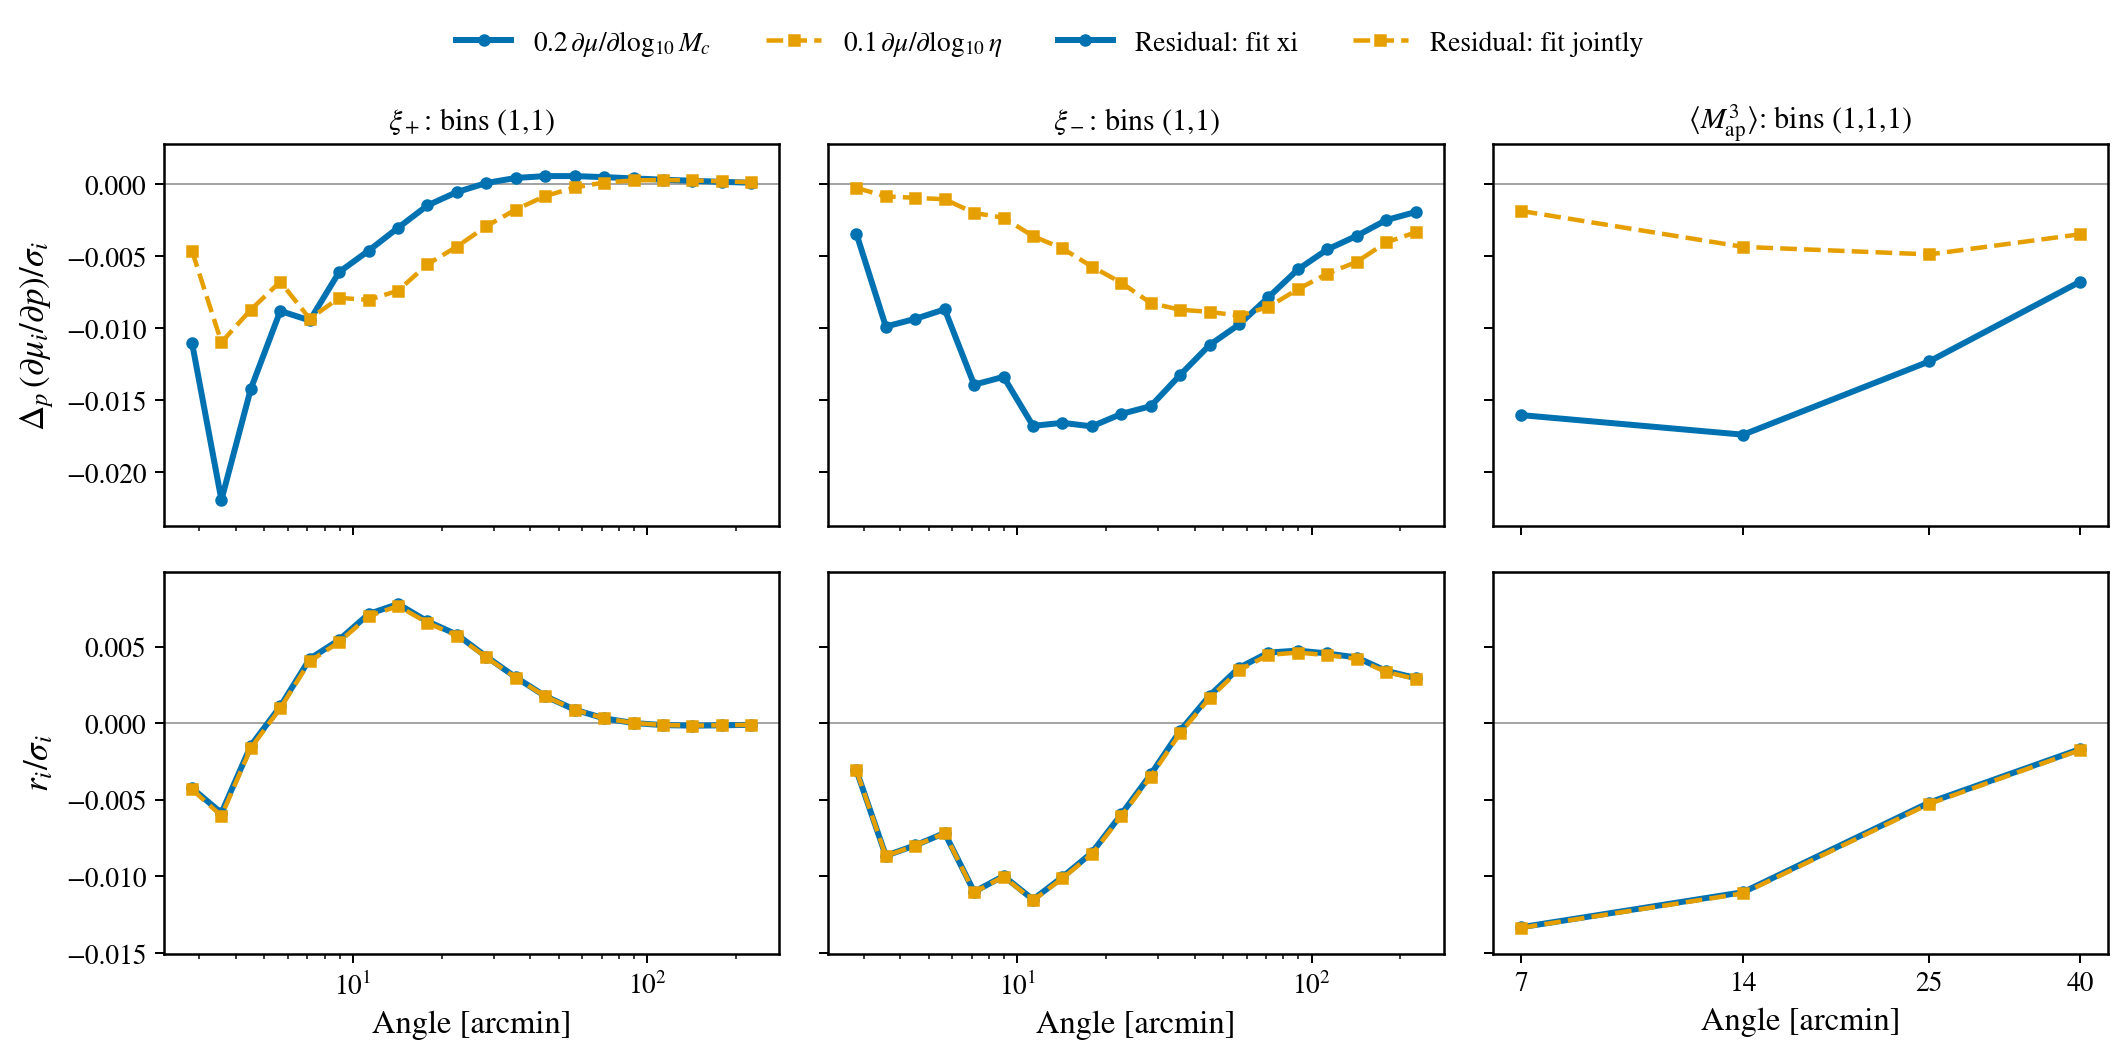

two_point signed template cosine: 0.7492050260598017
joint signed template cosine: 0.7889900539598879


In [5]:
derivatives = baseline["derivatives_h2"]
names = list(baseline["names"])
templates = response_plots.compare_templates(
    target=.2 * derivatives[:, names.index("M_c_baccoemu")],
    mimic=.1 * derivatives[:, names.index("eta_baccoemu")],
    covariance=baseline["covariance"], two_point=baseline["kind"] != "map3",
)
panels = []
for kind, title in (("xip", r"$\xi_+$: bins (1,1)"),
                    ("xim", r"$\xi_-$: bins (1,1)"),
                    ("map3", r"$\langle M_{\rm ap}^3\rangle$: bins (1,1,1)")):
    selected = (baseline["kind"] == kind) & (baseline["bins"][:, 0] == 0)
    selected &= baseline["bins"][:, 1] == 0
    coordinate_column = 2
    if kind == "map3":
        selected &= baseline["bins"][:, 2] == 0
        coordinate_column = 0
    indices = np.flatnonzero(selected)
    angle = baseline["angles"][indices, coordinate_column] * 180. * 60. / np.pi
    order = np.argsort(angle)
    indices = indices[order]
    panels.append({
        "coordinate": angle[order],
        "templates": templates["templates"][:, indices],
        "residuals": np.asarray([
            templates["two_point"]["residual"][indices],
            templates["joint"]["residual"][indices],
        ]),
        "title": title,
        "coordinate_label": "Angle [arcmin]",
    })
figure, axes = response_plots.plot_derivative_templates(
    panels=panels,
    parameter_labels=[r"$0.2\,\partial\mu/\partial\log_{10}M_c$",
                      r"$0.1\,\partial\mu/\partial\log_{10}\eta$"],
    figsize=(12., 6.), show=None,
)
plots.check_figure_labels(figure=figure)
figure.savefig(output / "feedback_derivatives.png", dpi=150, pad_inches=.2)
figure.savefig(output / "feedback_derivatives.pdf", pad_inches=.2)
plt.show()
for experiment in ("two_point", "joint"):
    print(experiment, "signed template cosine:", templates[experiment]["cosine"])

## Does the forecast depend on the continuation?

The model comparisons use the same central derivative formula and step sizes in every case. The baseline additionally retains five-point derivatives at steps $h$ and $h/2$. Comparing a two-point stencil for one model with a five-point stencil for another would mix derivative error with physical sensitivity.

The next figure compares joint errors under the neutrino and high-$k$ alternatives with the matching baseline central differences. The feedback FoM is the inverse square root of the determinant of the marginalized $(\log_{10}M_c,\log_{10}\eta)$ covariance. It is not a dark-energy FoM. The full 25-parameter YAML permits a separate $w_0w_a$ forecast, subject to the omitted response directions explained above.

The gray dashed line marks a ratio of one.

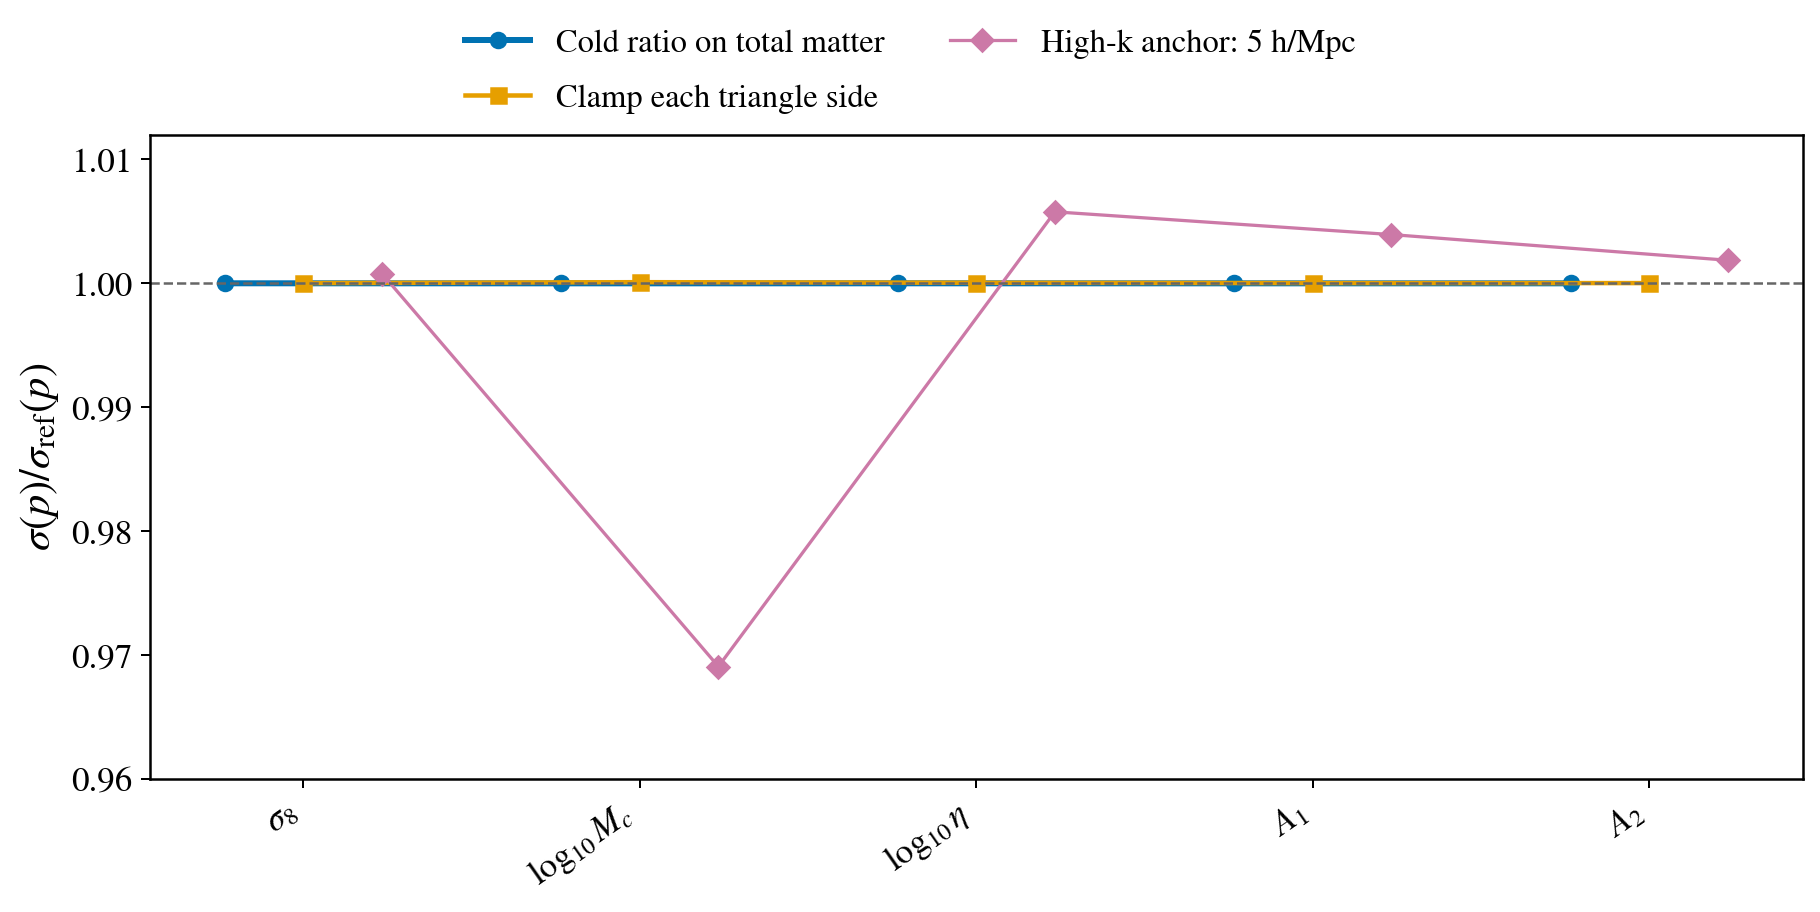

Baseline central {'joint': 3.4559959920619647, 'two_point': 2.47566981691687}
Baseline h {'joint': 3.456697854635792, 'two_point': 2.4762468317164203}
Baseline h2 {'joint': 3.456627727680537, 'two_point': 2.4761804485243766}
cold_on_total {'joint': 3.4559876549806785, 'two_point': 2.4756626768857157}
side_clamp {'joint': 3.455657394368064, 'two_point': 2.47566981691687}
high_k_5 {'joint': 3.544971204819626, 'two_point': 2.5462870305680925}
Doubled response k sampling: {'joint': 3.468335632154016, 'two_point': 2.4853033795241664}


In [6]:
alternatives = ["cold_on_total", "side_clamp", "high_k_5"]
resolved = True
for name in ["baseline"] + alternatives:
    if "central_sigma_joint" not in results[name]:
        resolved = False
        print(name, records[name]["forecasts"]["central"]["rank_status"])
if resolved:
    errors = []
    for name in alternatives:
        errors.append(results[name]["central_sigma_joint"])
    figure, axis = plots.plot_parameter_errors(
        names=list(study.PARAMETERS), errors=errors,
        errors_ref=baseline["central_sigma_joint"], labels=labels,
        legend=[
            "Cold ratio on total matter",
            "Clamp each triangle side",
            "High-k anchor: 5 h/Mpc",
        ],
        figsize=(10., 5.), show=None,
    )
    axis.set_ylim(bottom=0.96, top=1.012)
    plots.check_figure_labels(figure=figure)
    figure.savefig(output / "model_sensitivity.png", dpi=150, pad_inches=.2)
    figure.savefig(output / "model_sensitivity.pdf", pad_inches=.2)
    plt.show()
else:
    print("No model-error plot: at least one parameter space is unresolved.")
for stencil in ("central", "h", "h2"):
    print("Baseline", stencil, records["baseline"]["forecasts"][stencil]["feedback_fom"])
for name in alternatives:
    print(name, records[name]["forecasts"]["central"]["feedback_fom"])
scale_merits = records["feedback_k"]["forecasts"]["central"]["feedback_fom"]
print("Doubled response k sampling:", scale_merits)


## Check the derivatives, not only the mean

The next ratios compare two separate numerical changes. The first uses the five-point derivative with step $h/2$ divided by the result at $h$. The second doubles the BACCO scale intervals and compares central derivatives with central derivatives on the baseline grid. Each curve uses its own matching reference. These tests can reveal both noisy derivatives and smooth resolution errors; agreement at one fiducial is still not a calibration test.

Here $h$ denotes a finite-difference step for each varied parameter. It is unrelated to the dimensionless Hubble parameter, which is held fixed in this example.

The gray dashed line marks a ratio of one.

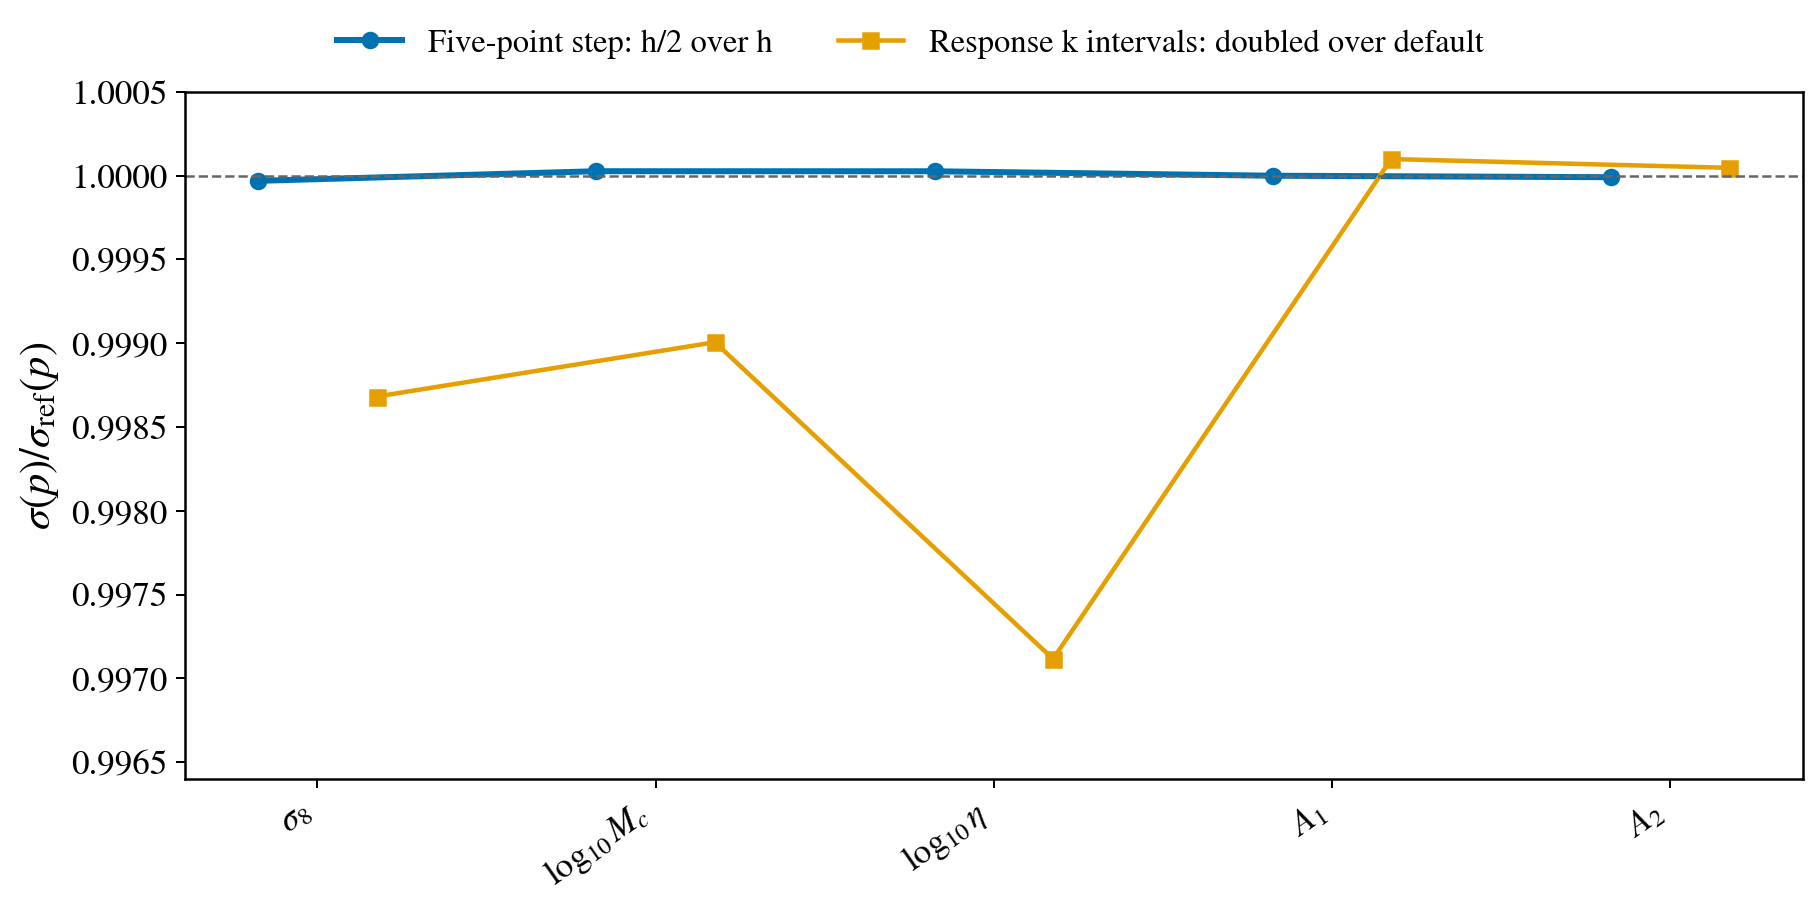

Step-refinement error ratios: [0.99996856 1.00002596 1.00002571 0.99999909 0.99999023]
Scale-refinement error ratios: [0.99868158 0.99900569 0.9971163  1.00009865 1.00004614]


In [7]:
required = ("h_sigma_joint", "h2_sigma_joint", "central_sigma_joint")
resolved = all(key in baseline for key in required)
resolved = resolved and "central_sigma_joint" in results["feedback_k"]
if resolved:
    ratios = [
        baseline["h2_sigma_joint"] / baseline["h_sigma_joint"],
        results["feedback_k"]["central_sigma_joint"] / baseline["central_sigma_joint"],
    ]
    figure, axis = plots.plot_parameter_errors(
        names=list(study.PARAMETERS), errors=ratios,
        errors_ref=np.ones(len(study.PARAMETERS)), labels=labels,
        legend=[
            "Five-point step: h/2 over h",
            "Response k intervals: doubled over default",
        ],
        figsize=(10., 5.), show=None,
    )
    axis.set_ylim(bottom=0.9964, top=1.0005)
    plots.check_figure_labels(figure=figure)
    figure.savefig(output / "derivative_accuracy.png", dpi=150, pad_inches=.2)
    figure.savefig(output / "derivative_accuracy.pdf", pad_inches=.2)
    plt.show()
    print("Step-refinement error ratios:", ratios[0])
    print("Scale-refinement error ratios:", ratios[1])
else:
    print("No derivative-error plot: a requested marginalized covariance is unresolved.")


## What remains to establish

The saved comparisons test this fiducial, these scales and a stated family of continuations. They do not bound every possible extrapolation or replace calibration of mixed cold-neutrino bispectra. The finite-triangle estimator, scalar pixel smoothing, source reconstruction, fixed covariance and DMO quadratic-IA assumptions remain visible in the YAML and [science guide](../../external_modules/code/cosmolike_core/theory/bacco_bispectrum/README.md#bacco). All 400 two-point rows are retained, including scales removed by published DES cuts.

A production forecast should release the remaining parameters, verify derivative stability when each response axis is refined, and test the scale selection. Mean stability alone is insufficient: numerical derivative noise can make a Fisher error spuriously small. [EXAMPLE_FISHER_ACCURACY.ipynb](EXAMPLE_FISHER_ACCURACY.ipynb) demonstrates the cheaper derivative-noise screen; a smooth, coherent derivative error still requires explicit refinement checks.

**We thank the BACCO authors and Pierre Burger and collaborators for the paired emulator and weights, and Sunao Sugiyama and Rafael Gomes for the three-point codes and analyses.** See [Burger et al.](https://arxiv.org/abs/2506.18974), [fastnc](https://github.com/git-sunao/fastnc/tree/tatt), [3pcf_integrator](https://github.com/rchgomes/3pcf_integrator), [the Y6 pipeline](https://github.com/rchgomes/desy6-3pcf), and the project [acknowledgements](README.md#acknowledgements).

In [8]:
summary = {
    "parameters": list(study.PARAMETERS),
    "covariance_fixed": True,
    "row_count": int(baseline["mean"].size),
    "delta_chi2": distances,
    "baseline_forecasts": records["baseline"]["forecasts"],
    "alternative_forecasts": {},
    "scale_grid_forecast": records["feedback_k"]["forecasts"],
    "identity": records["baseline"]["identity"],
    "reference_feedback": records["baseline"]["feedback_reference"],
    "calibration_claim": False,
}
for name in alternatives:
    summary["alternative_forecasts"][name] = records[name]["forecasts"]
for probe in ("two_point", "joint"):
    key = f"h2_sigma_{probe}"
    if key in baseline:
        summary[f"baseline_sigma_{probe}"] = baseline[key].tolist()
comparisons = (
    ("joint_over_two_point_errors", baseline, "h2_sigma_joint", "h2_sigma_two_point"),
    ("step_error_ratios", baseline, "h2_sigma_joint", "h_sigma_joint"),
    ("scale_grid_error_ratios", results["feedback_k"],
     "central_sigma_joint", "central_sigma_joint"),
)
for name, current, numerator, denominator in comparisons:
    if numerator in current and denominator in baseline:
        ratio = current[numerator] / baseline[denominator]
        summary[name] = ratio.tolist()
path = PROJECT / "chains/bacco_fisher_summary.json"
path.write_text(json.dumps(summary, indent=2, sort_keys=True, allow_nan=False) + "\n")
print(path)


/Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_3pcf/runs/bacco_fisher_summary.json
